# Stability of Dynamic Systems

## Stability Analysis

The objective of stability analysis is to determine how a dynamic system responds to small perturbations. If a system is slightly disturbed from an equilibrium state or a nominal trajectory, we'd like to know if it returns to the original state, remains nearby ordiverges away.

Consider a general nonlinear system

$$\dot{\mathbf{x}} = \mathbf{f}(\mathbf{x})$$

where:

- $\mathbf{x}$ = state vector
- $\mathbf{f}$ = system dynamics

An equilibrium point $\mathbf{x}_e$ satisfies

$$\mathbf{f}(\mathbf{x}_e)=0$$

meaning that if the system starts at $\mathbf{x}_e$, it remains there indefinitely.

To study stability, we introduce a small perturbation

$$\delta\mathbf{x} = \mathbf{x} - \mathbf{x}_e$$

and examine how it evolves with time. Near an equilibrium, the nonlinear dynamics can be approximated by a linear system:

$$\delta\dot{\mathbf{x}} = \mathbf{A}\delta\mathbf{x}$$

where

$$\mathbf{A}=\left.\frac{\partial \mathbf f}{\partial \mathbf x}\right|_{\mathbf{x}_e}$$

is the **Jacobian matrix** evaluated at the equilibrium; this linearized system captures the local behavior of the nonlinear system. The solution of

$$\delta\dot{\mathbf{x}} = \mathbf{A}\delta\mathbf{x}$$

is

$$\delta\mathbf{x}(t) = e^{\mathbf{A}t}\delta\mathbf{x}(0)$$

### Eigenvalues and Eigenvectors

The behavior of $e^{\mathbf{A}t}$ is completely determined by the **eigenvalues** and **eigenvectors** of $\mathbf{A}$. In linear algebra, an eigenvector of a linear transformation is a nonzero vector $\mathbf{v}$ that changes by a scalar factor when that linear transformation is applied to it:


The eigenvalue problem is

$$\mathbf{A}\mathbf{v} = \lambda\mathbf{v}$$

where:

- $\lambda$ = eigenvalue
- $\mathbf{v}$ = corresponding eigenvector

<center><img src="Images/eigenvector.png" alt="Drawing" style="width: 450px;"/><center>



Each eigenvector defines a special direction in the state space: the direction along which the perturbation stays aligned with the eigenvector and only changes magnitude according to $e^{\lambda t}$. Therefore:

1) Eigenvectors tell us where disturbances evolve
2) Eigenvalues tell us how fast they grow, decay, or oscillate

Eigenvalues are found by solving the equation $det(\mathbf{A} - \lambda \mathbf{I}) = 0$. For a $n \times n$ matrix we get $n$ eigenvalues. In general, they are complex numbers expressed in the form

$$ \lambda = \sigma \pm j\omega$$

, so they appear as complex conjugates pair. The general solution associated with an eigenvalue $\lambda$ is

$$ e^{\lambda t}=e^{\sigma + j\omega t} =e^{\sigma t}\left [\cos\left ( \omega t \right )+j\sin\left ( \omega t \right )\right ] $$


Both the real and imaginary parts play a crucial role in the system dynamics:

- The imaginary part $\omega$ determines the oscillatory behaviour of the solution: if $\omega \ne 0$, the solution oscillates over time, while for $\omega = 0$ the trend is monotonic
- The real part $\sigma$ determines the long-term behaviour of the solution: depending on the value (negative, zero or positive) we get an exponential decay, pure oscillatory of exponential grow respectively. This has an effect on the **stability** of the system



## Stability from Eigenvalues

Looking at the eigenvalues related to the state matrix $\mathbf A$ of a dynamic system we can understand whether it is stable or not. Specifically, the real part $\sigma$ is the one to be investigated.


### Stable Systems

- If all eigenvalues $\lambda_i$ of a dynamic system satisfy the condition $\sigma_i<0$ follows that, for $t \rightarrow \infty$

$$ e^{\lambda_i t} =e^{\sigma_i t}\left [\cos\left ( \omega t \right )+j\sin\left ( \omega t \right )\right ]\rightarrow 0$$



...and every perturbation decays over time; in this case the equilibrium is **asymptotically stable**.

- Instead, if eigenvalues lie exactly on the imaginary axis ($ \sigma_i = 0 $), then 

$$ e^{\lambda_i t} =\cos\left ( \omega t \right )+j\sin\left ( \omega t \right )$$

The perturbation neither grows nor decays: the motion is oscillatory and the system is **marginally stable**.

#### Example: Harmonic oscillator

This is a particularly useful example because it demonstrates how eigenvalues connect physical parameters to stability. Consider a mass-spring-damper system:

$$m\ddot{x}+c\dot{x}+kx=0$$

Introduce the state vector

$$\mathbf{x} = \begin{bmatrix} x\\ v \end{bmatrix}, \qquad v=\dot{x}$$

The first-order state equations are

$$\dot{x}=v, \dot{v}=-\frac{k}{m}x-\frac{c}{m}v$$

Therefore,

$$\dot{\mathbf{x}} = \begin{bmatrix} 0 & 1\\ -\dfrac{k}{m} & -\dfrac{c}{m} \end{bmatrix} \mathbf{x}$$

The characteristic equation is

$$\lambda^2+\frac{c}{m}\lambda+\frac{k}{m}=0$$

Its roots are

$$\lambda_{1,2} = -\frac{c}{2m} \pm \sqrt{ \left(\frac{c}{2m}\right)^2-\frac{k}{m} }$$

For $m>0$, $k>0$ and $c>0$, both eigenvalues have negative real parts.

Setting the damping coefficient $c$ to zero, the system matrix becomes

$$\mathbf{A} = \begin{bmatrix} 0 & 1\\ -\dfrac{k}{m} & 0 \end{bmatrix}$$

The eigenvalues are

$$\lambda_{1,2} = \pm j\sqrt{\frac{k}{m}}$$

The eigenvalues lie exactly on the imaginary axis. The solution is

$$x(t) = x_0\cos(\omega_n t) + \frac{v_0}{\omega}\sin(\omega_n t)$$

, where

$$\omega=\sqrt{\dfrac{k}{m}}$$

The motion remains bounded but does not converge to the origin. The equilibrium is stable in the Lyapunov sense, but not asymptotically stable.

System matrix:
[[ 0.   1. ]
 [-4.  -0.6]]

Eigenvalues:
[-0.3+1.97737199j -0.3-1.97737199j]


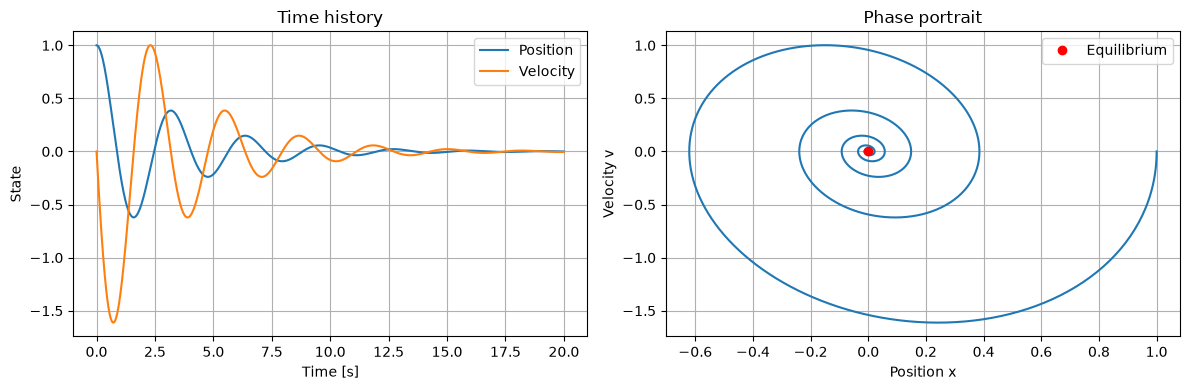

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from dynamic_systems import *


m = 1.0
k = 4.0
c = 0.6 # set c>0 for dumped motion, c=0 for undumped

solve_oscillator(m, k, c)

### Unstable Systems

- If at least one eigenvalue $\lambda_i$ of a dynamic system satisfy the condition $\sigma_i>0$ follows that, for $t \rightarrow \infty$

$$ e^{\lambda_i t} =e^{\sigma_i t}\left [\cos\left ( \omega t \right )+j\sin\left ( \omega t \right )\right ]\rightarrow \infty$$

...and a perturbation along this direction grows over time; in this case the equilibrium is **unstable**.



#### Example - Saddle-point instability

 Differential equations

Consider

$$\dot{x}=x, \dot{y}=-2y$$

In matrix form,

$$\begin{bmatrix} \dot{x}\\ \dot{y} \end{bmatrix} = \begin{bmatrix} 1 & 0\\ 0 & -2 \end{bmatrix} \begin{bmatrix} x\\ y \end{bmatrix}$$

The eigenvalues are

$$\lambda_1=1, \qquad \lambda_2=-2$$

One component grows while the other decays:

$$x(t)=x_0e^t, \qquad y(t)=y_0e^{-2t}$$

The system is unstable because stability requires all perturbation directions to remain bounded.

The code below show how $x$ and $y$ evolve over time for $x_0 = 0.05, y_0=1$


Eigenvalues:
[ 1.+0.j -2.+0.j]


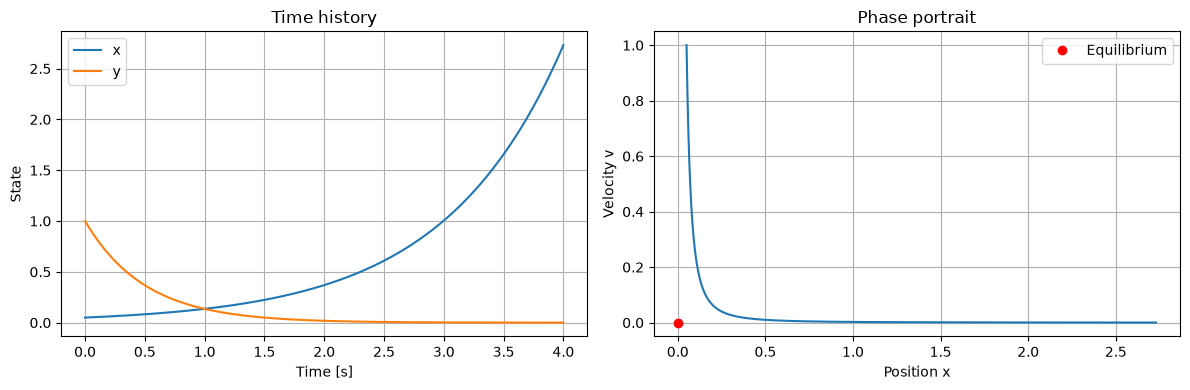

In [2]:
solve_saddle_system()


The $y$-axis is the stable eigendirection. A trajectory initialized exactly on this direction converges to the equilibrium. Any nonzero component along the unstable $x$-direction eventually dominates.

### Solution Classification in the state space

A ganeral classification of the dynamic system under consideration can be made by using the state space (or phase portrait) and looking at the values of $\sigma$ and $\omega$. Eigenvalues are written as 

$$ \lambda = \sigma \pm j\omega$$

In case of a two-dimensional state, we have two eigenvalues that belong to one of the following cases:

- **Case 1**: $\lambda_1$ and $\lambda_2$ are real ($\omega$ is zero):

$$\lambda_1 = \sigma_1, \qquad \lambda_2 = \sigma_2$$

<center><img src="Images/stability_sigma.png" alt="Drawing" style="width: 600px;"/><center>



- **Case 1**: $\lambda_1$ and $\lambda_2$ are complex conjugate ($\sigma_1 = \sigma_2 = \sigma$):

$$\lambda_1 = \sigma + j\omega, \qquad \lambda_2 = \sigma - j\omega$$

<center><img src="Images/stability_omega.png" alt="Drawing" style="width: 600px;"/><center>



### Special Cases

#### Van der Pol Oscillator

An equilibrium can be unstable even though the long-term system response remains bounded: the system exibit a **stable limit cycle**.

The differential equation of the Van der Pol equation is

$$\ddot{x} - \mu(1-x^2)\dot{x} + x=0, \qquad \mu>0$$

Using $v=\dot{x}, \dot{v} = \mu(1-x^2)v-x$ the equilibrium is $(x_e,v_e)=(0,0)$.

The Jacobian at the origin is

$$\mathbf{A} = \begin{bmatrix} 0 & 1\\ -1 & \mu \end{bmatrix}$$

For $\mu>0$, the trace is positive, so the origin is unstable. Nevertheless, trajectories approach a periodic orbit called a stable limit cycle.

For small values of $\mu$ (e.g., 0.1) the solution is nearly sinusoidal. As $\mu$ is incremented (e.g., 1) a clear limit cycle is formed.

Eigenvalues at the origin:
[0.5+0.8660254j 0.5-0.8660254j]


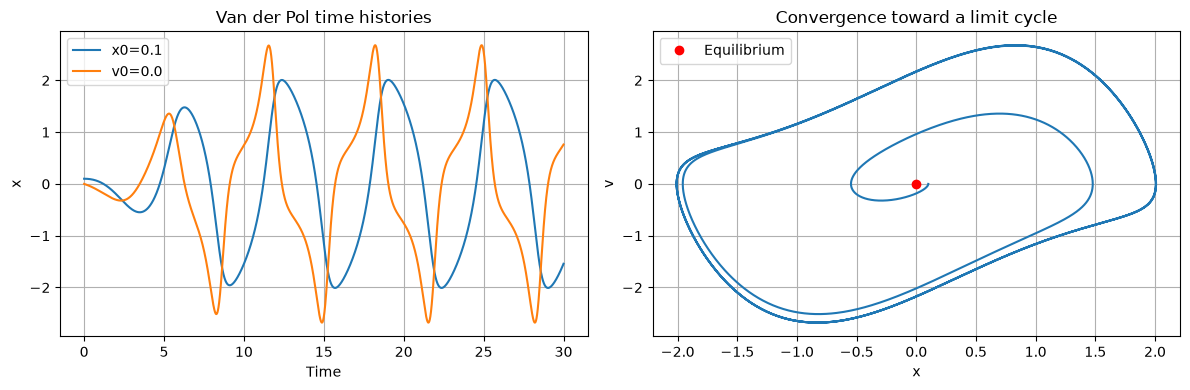

In [12]:
#### input data ####
mu = 1
x0 = 0.1
v0 = 0.0
####################

solve_vanderpol(mu, x0, v0)